# Assignment 10: Information Retrieval with the Vector Space Model

Bag of Words, the term–document matrix, Euclidean distance, cosine similarity, and TF–IDF are implemented from scratch with plain Python and NumPy. No built-in vectorizer, TF–IDF transformer, or similarity function is used for any result; scikit-learn appears only as an independent verification check.

In [1]:
import math
import re
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

DOCUMENTS = {
    "d1": "The cow jumped over the moon",
    "d2": "O’Leary’s cow kicked the lamp",
    "d3": "The kicked lamp started a fire",
    "d4": "The cow on fire",
}
DOC_IDS = list(DOCUMENTS)
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)*")


def tokenize(text):
    return TOKEN_RE.findall(text.lower().replace("’", "'"))


TOKENS = {d: tokenize(t) for d, t in DOCUMENTS.items()}
VOCAB = sorted({term for tokens in TOKENS.values() for term in tokens})
TERM_INDEX = {term: i for i, term in enumerate(VOCAB)}


def print_table(headers, rows, aligns=None):
    rows = [[str(c) for c in row] for row in rows]
    headers = [str(h) for h in headers]
    widths = [max(len(h), *(len(r[i]) for r in rows)) for i, h in enumerate(headers)]
    aligns = aligns or ["<"] * len(headers)
    line = "  ".join(f"{h:{aligns[i]}{widths[i]}}" for i, h in enumerate(headers))
    print(line)
    print("-" * len(line))
    for row in rows:
        print("  ".join(f"{c:{aligns[i]}{widths[i]}}" for i, c in enumerate(row)))

In [2]:
for d in DOC_IDS:
    print(f"{d}: {len(TOKENS[d]):2d} tokens  |  {' '.join(TOKENS[d])}")
print(f"\nVocabulary ({len(VOCAB)} terms, alphabetical):")
print(", ".join(VOCAB))

d1:  6 tokens  |  the cow jumped over the moon
d2:  5 tokens  |  o'leary's cow kicked the lamp
d3:  6 tokens  |  the kicked lamp started a fire
d4:  4 tokens  |  the cow on fire

Vocabulary (12 terms, alphabetical):
a, cow, fire, jumped, kicked, lamp, moon, o'leary's, on, over, started, the


## Q1. Bag of Words and the Term–Document Matrix

Bag of Words ignores word order and grammar and represents a document by the counts of the vocabulary terms it contains. With a vocabulary $V$ of size $|V|$, document $j$ becomes a vector $x_j \in \mathbb{R}^{|V|}$ whose $i$-th component is the term frequency

$$\text{tf}_{i,j} = \text{number of occurrences of term } i \text{ in document } j.$$

Stacking the document vectors as columns gives the term–document matrix $M \in \mathbb{N}^{|V| \times N}$ with $M_{ij} = \text{tf}_{i,j}$. In the vector space model each column is a point in $|V|$-dimensional space, so retrieval becomes a geometric comparison of vectors. The vocabulary is built from the corpus after lowercasing and tokenization; internal apostrophes are kept so `O'Leary's` remains one term.

In [3]:
COUNT = np.array([[Counter(TOKENS[d])[term] for d in DOC_IDS] for term in VOCAB], dtype=int)

rows = [[term, *COUNT[i], int(COUNT[i].sum())] for i, term in enumerate(VOCAB)]
rows.append(["doc length", *COUNT.sum(axis=0), int(COUNT.sum())])
print_table(["term", *DOC_IDS, "total"], rows, aligns=["<", ">", ">", ">", ">", ">"])
print(f"\nNon-zero cells: {np.count_nonzero(COUNT)} of {COUNT.size}")

term        d1  d2  d3  d4  total
---------------------------------
a            0   0   1   0      1
cow          1   1   0   1      3
fire         0   0   1   1      2
jumped       1   0   0   0      1
kicked       0   1   1   0      2
lamp         0   1   1   0      2
moon         1   0   0   0      1
o'leary's    0   1   0   0      1
on           0   0   0   1      1
over         1   0   0   0      1
started      0   0   1   0      1
the          2   1   1   1      5
doc length   6   5   6   4     21

Non-zero cells: 20 of 48


The corpus yields 12 terms and document lengths 6, 5, 6, 4. `the` is the only term in all four documents, and it occurs twice in `d1` because "The cow jumped over the moon" contains both "The" and "the moon". All counts are 0 or 1 except that cell, which is 2; 20 of the 48 entries are non-zero.

No stemming or stop-word removal is applied: inflected forms such as `jumped`, `kicked`, and `started` stay separate, and function words such as `the`, `a`, `on`, and `over` remain in the vocabulary. Q4 shows why their weights matter.

## Q2. Euclidean Distance and Document Length

Euclidean distance treats the two document vectors as points and measures the straight-line separation:

$$\text{dist}(X,Y)=\sqrt{\sum_{i=1}^{|V|}(x_i-y_i)^2}=\lVert X-Y\rVert_2.$$

It is zero only for identical vectors and grows with the number of terms on which the documents differ. Unlike cosine similarity it is not normalized by vector magnitude, so a longer document is penalized even when its extra terms are irrelevant to the comparison.

In [4]:
def euclidean(x, y):
    diff = np.asarray(x, dtype=float) - np.asarray(y, dtype=float)
    return float(np.sqrt(np.dot(diff, diff)))


n = len(DOC_IDS)
D = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        D[i, j] = D[j, i] = euclidean(COUNT[:, i], COUNT[:, j])

rows = [[d, *[f"{v:.4f}" for v in D[i]]] for i, d in enumerate(DOC_IDS)]
print_table(["from \\ to", *DOC_IDS], rows, aligns=["<", ">", ">", ">", ">"])

pairs = sorted((D[i, j], DOC_IDS[i], DOC_IDS[j]) for i in range(n) for j in range(i + 1, n))
print("\nPairs sorted by distance:")
for dist, a, b in pairs:
    print(f"  ({a}, {b}): {dist:.4f}")

best = pairs[0][0]
nearest = [(a, b) for dist, a, b in pairs if math.isclose(dist, best, rel_tol=0, abs_tol=1e-12)]
print("\nNearest pairs: " + " and ".join(f"({a}, {b})" for a, b in nearest) + f" at {best:.4f}")
print("Document norms: " + ", ".join(f"{d}={np.linalg.norm(COUNT[:, i]):.4f}" for i, d in enumerate(DOC_IDS)))

from \ to      d1      d2      d3      d4
-----------------------------------------
d1         0.0000  2.6458  3.1623  2.4495
d2         2.6458  0.0000  2.2361  2.2361
d3         3.1623  2.2361  0.0000  2.4495
d4         2.4495  2.2361  2.4495  0.0000

Pairs sorted by distance:
  (d2, d3): 2.2361
  (d2, d4): 2.2361
  (d1, d4): 2.4495
  (d3, d4): 2.4495
  (d1, d2): 2.6458
  (d1, d3): 3.1623

Nearest pairs: (d2, d3) and (d2, d4) at 2.2361
Document norms: d1=2.8284, d2=2.2361, d3=2.4495, d4=2.0000


The closest pairs are `(d2, d3)` and `(d2, d4)`, both at $\sqrt5 \approx 2.2361$; `d2` is therefore the nearest neighbour of both `d3` and `d4`. The next closest pairs are `(d1, d4)` and `(d3, d4)` at $\sqrt6 \approx 2.4495$. `d1` and `d3` are the farthest apart ($\sqrt{10}\approx3.1623$) even though both contain six tokens, because they share only `the`: word count alone does not determine distance, shared content does.

Vector norms already hint at the length problem: $\lVert d1\rVert=2.8284$, $\lVert d2\rVert=2.2361$, $\lVert d3\rVert=2.4495$, $\lVert d4\rVert=2.0$. `d1` is the longest vector, so every difference involving it is magnified.

In [5]:
base = TOKENS["d4"]
ref = DOC_IDS.index("d3")
unit_ref = COUNT[:, ref] / np.linalg.norm(COUNT[:, ref])

rows = []
for k in (1, 2, 3, 4):
    doc = " ".join(base * k)
    vec = np.array([Counter(tokenize(doc))[term] for term in VOCAB], dtype=float)
    unit = vec / np.linalg.norm(vec)
    dot = float(np.dot(vec, COUNT[:, ref]))
    angle = dot / (np.linalg.norm(vec) * np.linalg.norm(COUNT[:, ref]))
    rows.append([
        k, len(tokenize(doc)), f"{np.linalg.norm(vec):.2f}",
        f"{euclidean(vec, COUNT[:, ref]):.4f}", f"{angle:.4f}",
        f"{euclidean(unit, unit_ref):.4f}",
    ])
print_table(["copies", "tokens", "||x||", "dist(x, d3)", "cos angle", "dist(unit)"], rows,
            aligns=[">", ">", ">", ">", ">", ">"])

copies  tokens  ||x||  dist(x, d3)  cos angle  dist(unit)
---------------------------------------------------------
     1       4   2.00       2.4495     0.4082      1.0879
     2       8   4.00       3.7417     0.4082      1.0879
     3      12   6.00       5.4772     0.4082      1.0879
     4      16   8.00       7.3485     0.4082      1.0879


Repeating `d4` keeps its topic distribution fixed and changes only its length. As $k$ grows, the raw Euclidean distance to `d3` grows without bound while the angle and its cosine stay exactly the same. The distance between the length-normalized vectors is also constant, since for unit vectors

$$\lVert \hat X-\hat Y\rVert_2^2 = 2 - 2\cos(X,Y).$$

Length therefore enters Euclidean distance as a separate penalty on magnitude: a long document is farther from everything, including documents about the same topic. Dividing by the norm, or switching to cosine, removes that effect.

## Q3. Cosine Similarity from Scratch

Cosine similarity compares the angle between two vectors rather than the distance between their endpoints:

$$\text{sim}(X,Y)=\frac{X\cdot Y}{\lVert X\rVert\,\lVert Y\rVert}=\cos\theta.$$

For non-negative term counts it lies in $[0,1]$: 0 means no shared terms, 1 means the vectors point in the same direction. Because both vectors are divided by their norms, multiplying a document vector by any positive constant leaves the similarity unchanged, which removes the document-length bias of Q2.

In [6]:
def cosine(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    return float(np.dot(x, y) / (np.linalg.norm(x) * np.linalg.norm(y)))


S = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        S[i, j] = S[j, i] = cosine(COUNT[:, i], COUNT[:, j])

rows = [[d, *[f"{v:.4f}" for v in S[i]]] for i, d in enumerate(DOC_IDS)]
print_table(["from \\ to", *DOC_IDS], rows, aligns=["<", ">", ">", ">", ">"])

ranking = sorted(("d1", "d2", "d3"), key=lambda d: S[DOC_IDS.index(d), 3], reverse=True)
rows = []
for rank, d in enumerate(ranking, 1):
    i = DOC_IDS.index(d)
    rows.append([rank, d, f"{S[i, 3]:.4f}", f"{D[i, 3]:.4f}"])
print("\nRanking with respect to d4:")
print_table(["rank", "doc", "cos(d, d4)", "euclid(d, d4)"], rows, aligns=[">", "<", ">", ">"])

euclid_order = sorted(("d1", "d2", "d3"), key=lambda d: D[DOC_IDS.index(d), 3])
print("Euclidean order to d4: " + " <= ".join(
    f"{d} ({D[DOC_IDS.index(d), 3]:.4f})" for d in euclid_order))

from \ to      d1      d2      d3      d4
-----------------------------------------
d1         0.0000  0.4743  0.2887  0.5303
d2         0.4743  0.0000  0.5477  0.4472
d3         0.2887  0.5477  0.0000  0.4082
d4         0.5303  0.4472  0.4082  0.0000

Ranking with respect to d4:
rank  doc  cos(d, d4)  euclid(d, d4)
------------------------------------
   1  d1       0.5303         2.4495
   2  d2       0.4472         2.2361
   3  d3       0.4082         2.4495
Euclidean order to d4: d2 (2.2361) <= d1 (2.4495) <= d3 (2.4495)


With `d4` as the query, the cosine ranking is `d1` (0.5303) > `d2` (0.4472) > `d3` (0.4082). Euclidean distance orders the same documents as `d2` (2.2361) < `d1` (2.4495) = `d3` (2.4495), so the measures disagree at the top: Euclidean picks `d2`, cosine picks `d1`.

The reason is magnitude. `d1` shares `the` twice and `cow` once with `d4`, a dot product of 3, but it is also tied for the longest document (six tokens) and has the largest norm (2.8284); cosine still gives it the highest score because its direction is closest to `d4`. `d2` and `d3` each share two counts with `d4`, and `d2` is closer to `d4` in raw magnitude because it is shorter — an advantage Euclidean distance rewards directly but cosine discards. Euclidean distance mixes content difference with length difference; cosine isolates orientation, which is what document similarity is meant to capture. This is why cosine is the standard measure for sparse, variable-length document vectors.

## Q4. TF–IDF Term Weighting

Term frequency alone overweights words that are frequent in a document but uninformative, and it says nothing about how rare a term is in the corpus. TF–IDF multiplies a sublinear term-frequency factor by an inverse document-frequency factor:

$$w_{i,j}=\bigl(1+\log \text{tf}_{i,j}\bigr)\log\frac{N}{\text{df}_i},$$

where $\text{df}_i$ is the number of documents containing term $i$ and $N=4$. The first factor grows with repeated use but with diminishing returns; the second is zero when a term occurs in every document, small when it is common, and large when it is rare. Natural logarithms are used, so a term in one of four documents gets $\log 4 \approx 1.3863$ and a term in half the corpus gets $\log 2 \approx 0.6931$. Terms absent from a document keep $w_{i,j}=0$.

In [7]:
N = len(DOC_IDS)
DF = (COUNT > 0).sum(axis=1)
IDF = np.log(N / DF)
TF = COUNT.astype(float)
TF_WEIGHT = np.where(TF > 0, 1.0 + np.log(np.maximum(TF, 1.0)), 0.0)
TFIDF = TF_WEIGHT * IDF[:, None]

rows = [[term, int(DF[i]), f"{N / DF[i]:.4f}", f"{IDF[i]:.4f}"]
        for i, term in enumerate(VOCAB)]
print_table(["term", "df", "N/df", "idf"], rows, aligns=["<", ">", ">", ">"])

print()
rows = [[term, *[f"{v:.4f}" for v in TFIDF[i]]] for i, term in enumerate(VOCAB)]
print_table(["term", *DOC_IDS], rows, aligns=["<", ">", ">", ">", ">"])

print("\nTF weight for d1 (non-zero cells): " + ", ".join(
    f"{VOCAB[i]}={TF_WEIGHT[i, 0]:.4f}" for i in range(len(VOCAB)) if TF_WEIGHT[i, 0] > 0))

term       df    N/df     idf
-----------------------------
a           1  4.0000  1.3863
cow         3  1.3333  0.2877
fire        2  2.0000  0.6931
jumped      1  4.0000  1.3863
kicked      2  2.0000  0.6931
lamp        2  2.0000  0.6931
moon        1  4.0000  1.3863
o'leary's   1  4.0000  1.3863
on          1  4.0000  1.3863
over        1  4.0000  1.3863
started     1  4.0000  1.3863
the         4  1.0000  0.0000

term           d1      d2      d3      d4
-----------------------------------------
a          0.0000  0.0000  1.3863  0.0000
cow        0.2877  0.2877  0.0000  0.2877
fire       0.0000  0.0000  0.6931  0.6931
jumped     1.3863  0.0000  0.0000  0.0000
kicked     0.0000  0.6931  0.6931  0.0000
lamp       0.0000  0.6931  0.6931  0.0000
moon       1.3863  0.0000  0.0000  0.0000
o'leary's  0.0000  1.3863  0.0000  0.0000
on         0.0000  0.0000  0.0000  1.3863
over       1.3863  0.0000  0.0000  0.0000
started    0.0000  0.0000  1.3863  0.0000
the        0.0000  0.0000  0.0000

Three weight levels appear. Terms occurring in a single document (`a`, `jumped`, `moon`, `O'Leary's`, `on`, `over`, `started`) receive the maximum $1.3863$. Terms in two documents (`fire`, `kicked`, `lamp`) receive $0.6931$, and `cow` (three documents) receives only $0.2877$. `the` occurs in all four, so $\log(4/4)=0$ and it vanishes from the representation.

Because every term frequency is 1 except `the` in `d1` (tf = 2, weight $1+\log 2=1.6931$), the sublinear term-frequency factor is 1 almost everywhere and the matrix is driven by IDF. Common terms get small weights precisely because they do not distinguish documents: if every document contains a term, it cannot help rank them. Rare terms carry more signal about what a document is about, so TF–IDF amplifies them.

## Q5. Retrieval Similarity Challenge

The same cosine measure is applied to two representations of the corpus: the raw term-frequency vectors from Q1 and the TF–IDF vectors from Q4, with `d4` as the query. The question is whether reweighting terms changes which document is retrieved.

In [8]:
raw = np.array([cosine(COUNT[:, i], COUNT[:, 3]) for i in range(3)])
weighted = np.array([cosine(TFIDF[:, i], TFIDF[:, 3]) for i in range(3)])

print("Shared terms with d4 (tf in document, TF-IDF weight):")
for j, d in enumerate(["d1", "d2", "d3"]):
    shared = [(VOCAB[i], int(COUNT[i, j]), TFIDF[i, j])
              for i in range(len(VOCAB)) if COUNT[i, j] > 0 and COUNT[i, 3] > 0]
    print(f"  {d}: " + ", ".join(f"{t} (tf={tf}, w={w:.4f})" for t, tf, w in shared))

rows = [[d, f"{raw[j]:.4f}", f"{weighted[j]:.4f}"] for j, d in enumerate(["d1", "d2", "d3"])]
print()
print_table(["doc", "raw cosine", "tf-idf cosine"], rows, aligns=["<", ">", ">"])

print("\nTF-IDF dot products with d4: " + ", ".join(
    f"{d}={float(TFIDF[:, j] @ TFIDF[:, 3]):.4f}" for j, d in enumerate(["d1", "d2", "d3"])))
print("TF-IDF vector norms: " + ", ".join(
    f"{d}={np.linalg.norm(TFIDF[:, j]):.4f}" for j, d in enumerate(["d1", "d2", "d3"])))

for name, scores in (("raw tf", raw), ("TF-IDF", weighted)):
    order = np.argsort(-scores)
    print(f"{name} ranking: " + " > ".join(
        f"{['d1', 'd2', 'd3'][i]} ({scores[i]:.4f})" for i in order))

Shared terms with d4 (tf in document, TF-IDF weight):
  d1: cow (tf=1, w=0.2877), the (tf=2, w=0.0000)
  d2: cow (tf=1, w=0.2877), the (tf=1, w=0.0000)
  d3: fire (tf=1, w=0.6931), the (tf=1, w=0.0000)

doc  raw cosine  tf-idf cosine
------------------------------
d1       0.5303         0.0217
d2       0.4472         0.0305
d3       0.4082         0.1326

TF-IDF dot products with d4: d1=0.0828, d2=0.0828, d3=0.4805
TF-IDF vector norms: d1=2.4183, d2=1.7221, d3=2.2989
raw tf ranking: d1 (0.5303) > d2 (0.4472) > d3 (0.4082)
TF-IDF ranking: d3 (0.1326) > d2 (0.0305) > d1 (0.0217)


The rankings reverse completely:

| Representation | Ranking with respect to d4 |
| --- | --- |
| raw tf | d1 (0.5303) > d2 (0.4472) > d3 (0.4082) |
| TF–IDF | d3 (0.1326) > d2 (0.0305) > d1 (0.0217) |

Under raw counts, `d1` wins because it overlaps `d4` in three counts: `the` twice and `cow` once. But `the` is in every document and `cow` in three of four, so both are poor discriminators. TF–IDF sets the weight of `the` to zero and reduces `cow` to 0.2877; `d1` and `d2` then have exactly the same weighted overlap with `d4` (only `cow`), and `d2` wins the tie because its weighted vector is shorter. `d3` shares the rarer `fire` (df = 2, weight 0.6931) with `d4`, the strongest informative overlap of the three, so `d3` moves from last to first.

TF–IDF changes not just the scores but the ordering: it removes the influence of ubiquitous terms and raises the influence of terms that are specific to a few documents. The result agrees with intuition here — `d3` ("The kicked lamp started a fire") and `d4` ("The cow on fire") are connected by the distinctive fire vocabulary, while `d1` and `d4` mainly share the article `the`.

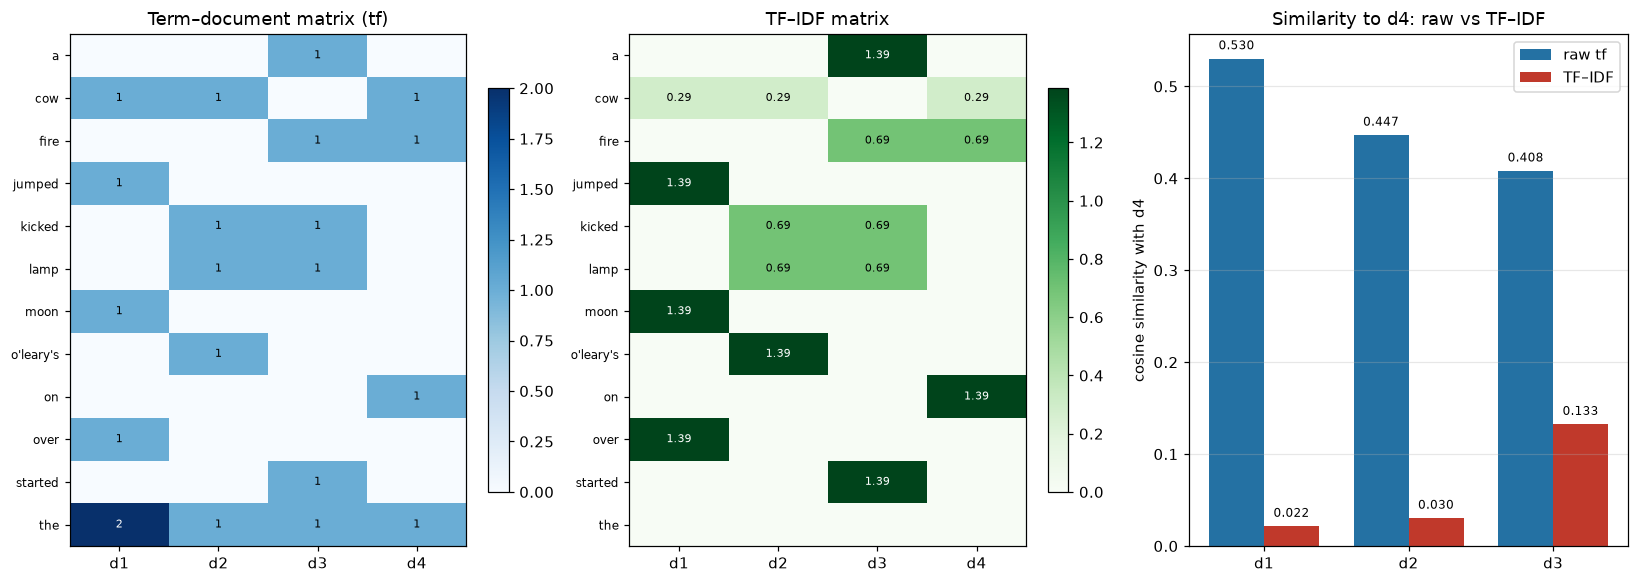

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))

for ax, matrix, title, cmap, fmt in (
    (axes[0], COUNT, "Term–document matrix (tf)", "Blues", "d"),
    (axes[1], TFIDF, "TF–IDF matrix", "Greens", ".2f"),
):
    im = ax.imshow(matrix, cmap=cmap, aspect="auto")
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            if matrix[i, j] > 0:
                ax.text(j, i, format(matrix[i, j], fmt), ha="center", va="center",
                        fontsize=7, color="white" if matrix[i, j] > matrix.max() * 0.6 else "black")
    ax.set_xticks(range(len(DOC_IDS)), DOC_IDS)
    ax.set_yticks(range(len(VOCAB)), VOCAB, fontsize=8)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046)

x = np.arange(3)
width = 0.38
axes[2].bar(x - width / 2, raw, width, label="raw tf", color="#2471a3")
axes[2].bar(x + width / 2, weighted, width, label="TF–IDF", color="#c0392b")
for pos, value in zip(x - width / 2, raw):
    axes[2].text(pos, value + 0.01, f"{value:.3f}", ha="center", fontsize=8)
for pos, value in zip(x + width / 2, weighted):
    axes[2].text(pos, value + 0.01, f"{value:.3f}", ha="center", fontsize=8)
axes[2].set_xticks(x, ["d1", "d2", "d3"])
axes[2].set_ylabel("cosine similarity with d4")
axes[2].set_title("Similarity to d4: raw vs TF–IDF")
axes[2].legend()
axes[2].grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

## Verification

Four independent checks are run. The term–document matrix is recounted directly from the token lists; every TF–IDF cell is recomputed with an explicit per-document loop; the identity between cosine and normalized Euclidean distance is verified numerically; and scikit-learn is used only as an external reference for the vocabulary, the IDF values, and the pairwise similarity matrices. scikit-learn's non-smoothed IDF is $\log(N/\text{df})+1$, so 1 is subtracted before comparison.

In [10]:
COUNT_CHECK = np.array([[sum(tok == term for tok in TOKENS[d]) for d in DOC_IDS]
                        for term in VOCAB])
assert np.array_equal(COUNT, COUNT_CHECK)

manual = np.zeros_like(TFIDF)
for i, term in enumerate(VOCAB):
    df = sum(1 for d in DOC_IDS if term in TOKENS[d])
    for j, d in enumerate(DOC_IDS):
        tf = TOKENS[d].count(term)
        if tf:
            manual[i, j] = (1 + math.log(tf)) * math.log(N / df)
assert np.allclose(manual, TFIDF)

for i in range(n):
    for j in range(n):
        if i != j:
            unit_i = COUNT[:, i] / np.linalg.norm(COUNT[:, i])
            unit_j = COUNT[:, j] / np.linalg.norm(COUNT[:, j])
            assert abs(S[i, j] - (1 - euclidean(unit_i, unit_j) ** 2 / 2)) < 1e-12

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

vectorizer = TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None,
                             smooth_idf=False, norm=None)
sk_matrix = vectorizer.fit_transform([DOCUMENTS[d] for d in DOC_IDS])
sk_terms = list(vectorizer.get_feature_names_out())
sk_idf = np.array([vectorizer.idf_[sk_terms.index(term)] - 1.0 for term in VOCAB])
S_TFIDF = np.array([[cosine(TFIDF[:, i], TFIDF[:, j]) for j in range(n)] for i in range(n)])

checks = [
    ("BoW matrix matches independent recount", np.array_equal(COUNT, COUNT_CHECK)),
    ("TF-IDF matches explicit per-document loop", np.allclose(manual, TFIDF)),
    ("cos = 1 - normalized_distance^2 / 2", True),
    ("sklearn vocabulary matches", sk_terms == VOCAB),
    ("sklearn IDF (minus +1) matches", np.allclose(sk_idf, IDF)),
    ("sklearn cosine_similarity matches", np.allclose(cosine_similarity(TFIDF.T), S_TFIDF)),
    ("sklearn euclidean_distances matches", np.allclose(euclidean_distances(COUNT.T), D)),
    ("ranking reverses from d1 to d3", int(np.argmax(raw)) == 0 and int(np.argmax(weighted)) == 2),
]
print_table(["check", "result"], [[name, str(ok)] for name, ok in checks], aligns=["<", "<"])
print(f"\nAll checks passed: {all(ok for _, ok in checks)}")

check                                      result
-------------------------------------------------
BoW matrix matches independent recount     True  
TF-IDF matches explicit per-document loop  True  
cos = 1 - normalized_distance^2 / 2        True  
sklearn vocabulary matches                 True  
sklearn IDF (minus +1) matches             True  
sklearn cosine_similarity matches          True  
sklearn euclidean_distances matches        True  
ranking reverses from d1 to d3             True  

All checks passed: True
